# Using SIMPLEOmics to integrate simulated spatial RNA-ATAC data

## 1. Load packages

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import SIMPLEOmics

# the location of R (used for the mclust clustering)
import os
os.environ['R_HOME'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/R"
os.environ['R_USER'] = "/home/lvyz/miniconda3/envs/SIMPLEOmics_env/lib/python3.8/site-packages/rpy2"

import scanpy as sc
import numpy as np
from scipy.sparse import csr_matrix
import torch
used_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(torch.cuda.is_available())
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "svg.fonttype": "none"
})

# set seed
seed=2026
SIMPLEOmics.ST_utils.fix_seed(seed)

True


## 2. Load data and preprocessing for training

In [ ]:
#load data
n_cluster = 10
file_fold = '/data_SIMPLEOmics/simulation/'
section_ids = ['adata_RNA','adata_ATAC']
adata_rna = sc.read_h5ad(file_fold + 'adata_RNA.h5ad')
adata_atac = sc.read_h5ad(file_fold + 'adata_ATAC.h5ad')
# annotation
adata_rna.obs['Ground Truth'] = adata_rna.obs['spatial_domain']
adata_atac.obs['Ground Truth'] = adata_atac.obs['spatial_domain']

adata_rna.var_names_make_unique()
adata_atac.var_names_make_unique()

# RNA
if isinstance(adata_rna.X, np.ndarray):
    adata_rna.X = csr_matrix(adata_rna.X)
sc.pp.filter_genes(adata_rna, min_cells=10)
sc.pp.highly_variable_genes(adata_rna, flavor="seurat_v3", n_top_genes=5000)
sc.pp.normalize_total(adata_rna, target_sum=1e4)
sc.pp.log1p(adata_rna)
sc.pp.scale(adata_rna)
adata_rna =  adata_rna[:, adata_rna.var['highly_variable']]
adata_rna.obsm["feat"] = SIMPLEOmics.ST_utils.pca(adata_rna,n_comps=60,random_state=seed)
adata_rna=SIMPLEOmics.Cal_Net(adata_rna)

# ATAC
from muon import atac as ac
ac.pp.tfidf(adata_atac, scale_factor=1e4)
sc.pp.normalize_per_cell(adata_atac, counts_per_cell_after=1e4)
sc.pp.log1p(adata_atac)
adata_atac.obsm["feat"] = SIMPLEOmics.ST_utils.pca(adata_atac,n_comps=60,random_state=seed,save_model=True,model_key="pca_model")
adata_atac=SIMPLEOmics.Cal_Net(adata_atac)

------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 30000
------Calculating Spatial Graph (k=6, metric=euclidean)...
Spatial edges: 30000


## 3. Training SIMPLEOmics

In [3]:
# training SIMPLEOmics
adata_rna,adata_atac=SIMPLEOmics.train(adata_rna,adata_atac,num_prototype=n_cluster,device=used_device,random_seed=seed)

training SIMPLEOmics...


100%|██████████| 1000/1000 [04:14<00:00,  3.93it/s]


## 4. Clustering

In [4]:
# clustering
SIMPLEOmics.ST_utils.mclust_R(adata_rna, num_cluster=n_cluster, used_obsm='SIMPLEOmics',random_seed=seed)

# ari
adata_rna = adata_rna[adata_rna.obs['Ground Truth']!='unknown']
from sklearn.metrics import adjusted_rand_score as ari_score
ari = ari_score(adata_rna.obs['Ground Truth'], adata_rna.obs['mclust'])
print('mclust, ARI = %01.3f' % ari_score(adata_rna.obs['Ground Truth'], adata_rna.obs['mclust']))

# rna embedding and atac embedding clustering
adata_rna1 = adata_rna.copy()
adata_rna2 = adata_rna.copy()
SIMPLEOmics.ST_utils.mclust_R(adata_rna1, num_cluster=n_cluster, used_obsm='omic1_embedding',random_seed=seed)
SIMPLEOmics.ST_utils.mclust_R(adata_rna2, num_cluster=n_cluster, used_obsm='omic2_embedding',random_seed=seed)

adata_rna.obs["mclust"] = adata_rna.obs["mclust"].astype(int).astype("category")
adata_rna1.obs["mclust"] = adata_rna1.obs["mclust"].astype(int).astype("category")
adata_rna2.obs["mclust"] = adata_rna2.obs["mclust"].astype(int).astype("category")

R[write to console]:     __  ___________    __  _____________
   /  |/  / ____/ /   / / / / ___/_  __/
  / /|_/ / /   / /   / / / /\__ \ / /   
 / /  / / /___/ /___/ /_/ /___/ // /    
/_/  /_/\____/_____/\____//____//_/    version 5.4.7
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%
mclust, ARI = 0.960
fitting ...
  |======================================================================| 100%
fitting ...
  |======================================================================| 100%


## 5. Visualization

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


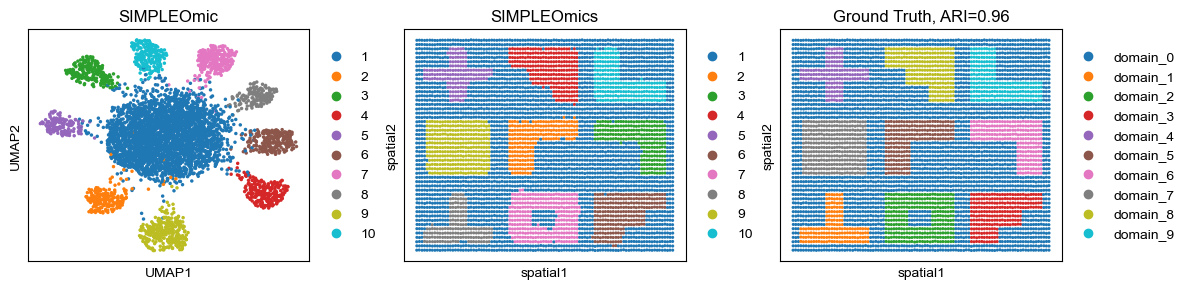

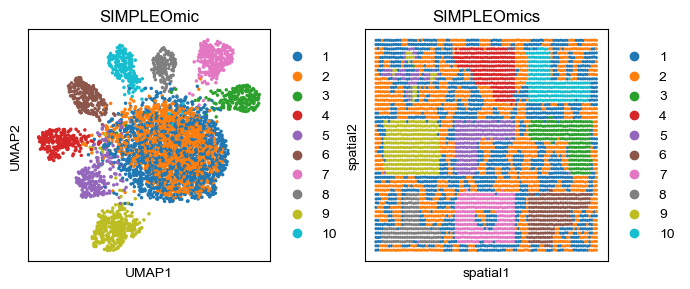

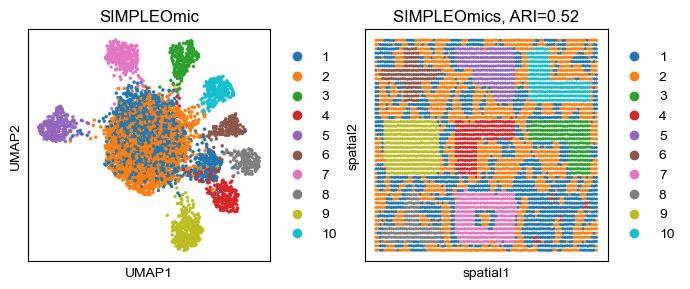

In [5]:
# visualization
fig, ax_list = plt.subplots(1, 3, figsize=(12, 3))
sc.pp.neighbors(adata_rna, use_rep='SIMPLEOmics')
sc.tl.umap(adata_rna)
sc.pl.umap(adata_rna, color='mclust', ax=ax_list[0], title='SIMPLEOmic', s=25, show=False)
sc.pl.embedding(adata_rna, basis='spatial', color='mclust', ax=ax_list[1], title='SIMPLEOmics', s=20, show=False)
sc.pl.embedding(adata_rna, basis='spatial', color='Ground Truth', ax=ax_list[2],title='Ground Truth, ARI='+str(round(ari,2)), s=20, show=False)
plt.tight_layout(w_pad=0.3)
plt.show()

ari_1 = ari_score(adata_rna1.obs['Ground Truth'], adata_rna1.obs['mclust'])
fig, ax_list = plt.subplots(1, 2, figsize=(7, 3))
sc.pp.neighbors(adata_rna1, use_rep='omic1_embedding')
sc.tl.umap(adata_rna1)
sc.pl.umap(adata_rna1, color='mclust', ax=ax_list[0], title='SIMPLEOmic', s=25, show=False)
sc.pl.embedding(adata_rna1, basis='spatial', color='mclust', ax=ax_list[1], title='SIMPLEOmics', s=20, show=False)
plt.tight_layout(w_pad=0.3)
plt.show()

ari_2 = ari_score(adata_rna2.obs['Ground Truth'], adata_rna2.obs['mclust'])
fig, ax_list = plt.subplots(1, 2, figsize=(7, 3))
sc.pp.neighbors(adata_rna2, use_rep='omic2_embedding')
sc.tl.umap(adata_rna2)
sc.pl.umap(adata_rna2, color='mclust', ax=ax_list[0], title='SIMPLEOmic', s=25, show=False)
sc.pl.embedding(adata_rna2, basis='spatial', color='mclust', ax=ax_list[1], title='SIMPLEOmics, ARI='+str(round(ari_2,2)), s=20, show=False)
plt.tight_layout(w_pad=0.3)
plt.show()